#  Generative AI in Data Analytics and Business Intelligence.
## Automated report generation


- AI creates real-time business reports, dashboards, and executive summaries, reducing manual effort and improving efficiency.
- Exploration in code using sales.csv as sample data;

# Complex dataset
### Loading the dataset.

In [41]:
import pandas as pd  

# Load the dataset  
file_path = "WA_Fn-UseC_-Telco-Customer-Churn.csv"  
df = pd.read_csv(file_path)  

# Display basic information  
print(df.head())    

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

### Basic information

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [43]:
# Check for missing values
missing_values = df.isnull().sum()
print(missing_values)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [44]:
# Count of unique values in categorical columns
categorical_count = df.nunique()
print(categorical_count)

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64


In [45]:
# Summary statistics for numerical columns
summary_stats = df.describe()
print(summary_stats)

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000


In [46]:
# Count of customers who churned vs. stayed
churn_counts = df['Churn'].value_counts()
print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


### Data visualisation for more insights

- Analyzing what factors influence churn by comparing groups.

##### Comparing churn rate across contract types

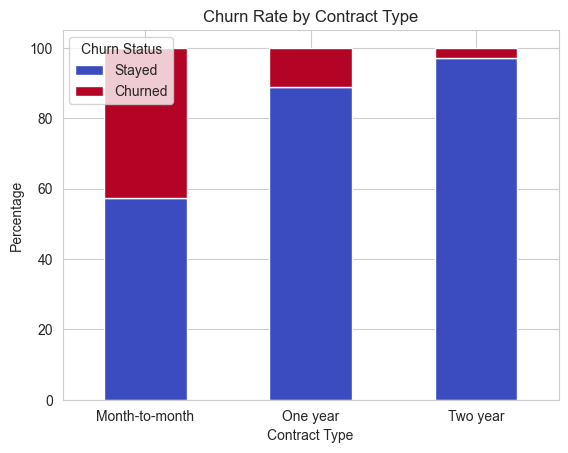

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

# Group by contract type and compute churn rate
contract_churn = df.groupby("Contract")["Churn"].value_counts(normalize=True).unstack() * 100

# Plot
contract_churn.plot(kind="bar", stacked=True, colormap="coolwarm")
plt.title("Churn Rate by Contract Type")
plt.ylabel("Percentage")
plt.xlabel("Contract Type")
plt.legend(title="Churn Status", labels=["Stayed", "Churned"])
plt.xticks(rotation=0)
plt.show()


##### Interpretation and insights.
1. Month-to-month contracts have the highest churn rate. This indicates that customers on month-to-month contracts are much more likely to churn.

2. Longer contracts lead to lower churn rates. As the contract length increases (from one year to two years), churned decreases while stayed increases. This suggests that customers who commit to longer contracts are more likely to remain customers.

3. Significant difference in churn between month-to-month and longer contracts. There's a substantial drop in churn rate when moving from month-to-month contracts to one-year contracts. The difference between one-year and two-year is smaller, but still significant.

##### Business Implications

This graph highlights the importance of contract length in customer retention.  The company could consider strategies to encourage customers to sign longer-term contracts to reduce churn.  Some potential strategies include:
- Offering discounts or incentives for longer contracts.
- Highlighting the benefits of long-term contracts.
- Improving customer satisfaction to reduce churn across all contract types.

In summary, the graph demonstrates a clear inverse relationship between contract length and churn rate, emphasizing the importance of encouraging longer-term contracts to improve customer retention.

##### Comparing Churn by Payment Method

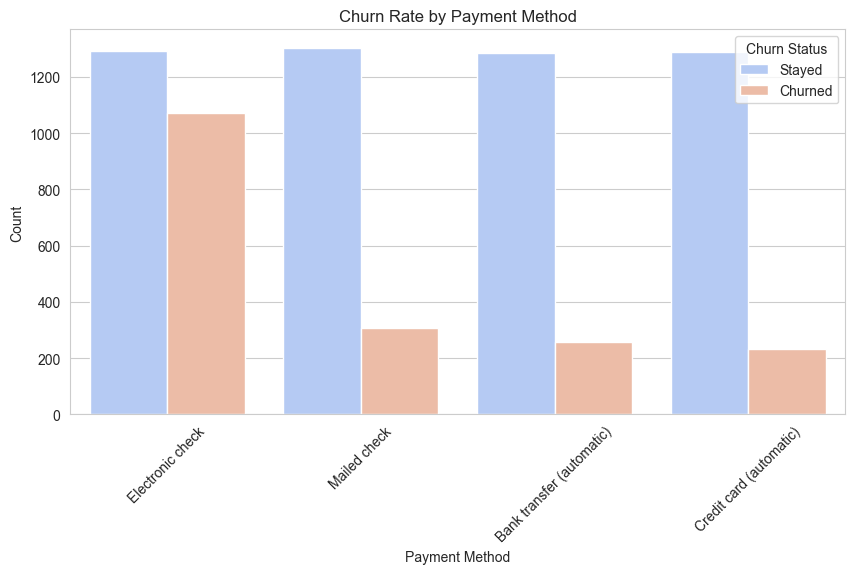

In [48]:
# Import required libraries
import seaborn as sns
import matplotlib.pyplot as plt

# Set style
sns.set_style("whitegrid")

# Plot churn distribution across payment methods
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="PaymentMethod", hue="Churn", palette="coolwarm")
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title="Churn Status", labels=["Stayed", "Churned"])
plt.show()

##### Interpretation and insights
1. Electronic check has the highest churn rate. This indicates that customers paying with electronic checks are much more likely to churn.

2. Automatic payment methods (Bank transfer and Credit card) have the lowest churn rates. This suggests that customers who use automatic payment methods are more likely to remain customers.

3. Mailed check has a moderate churn rate. The churn rate for mailed checks is higher than automatic payments but lower than electronic checks.

4. Overall customer base is higher for electronic checks and mailed checks. The total height of the bars for electronic checks and mailed checks is greater than the total height of the bars for automatic payments. This indicates a larger customer base using these methods.

##### Business Implications

This graph highlights the impact of payment methods on customer retention.  The company could consider strategies to reduce churn associated with electronic checks and encourage the adoption of automatic payment methods. Some potential strategies include:
- Incentivizing automatic payments.
- Understanding the reasons behind high churn with electronic checks (e.g., payment failures, perceived inconvenience).
- Providing clear instructions and support for setting up automatic payments.
- Potentially phasing out electronic checks or making them less prominent if the churn is significantly problematic.

In summary, the graph demonstrates a clear correlation between payment method and churn rate, with automatic payments leading to the lowest churn and electronic checks leading to the highest.  The company should focus on strategies to encourage automatic payments to improve customer retention.

##### Comparing Churn by Tenure (How long a customer has stayed)

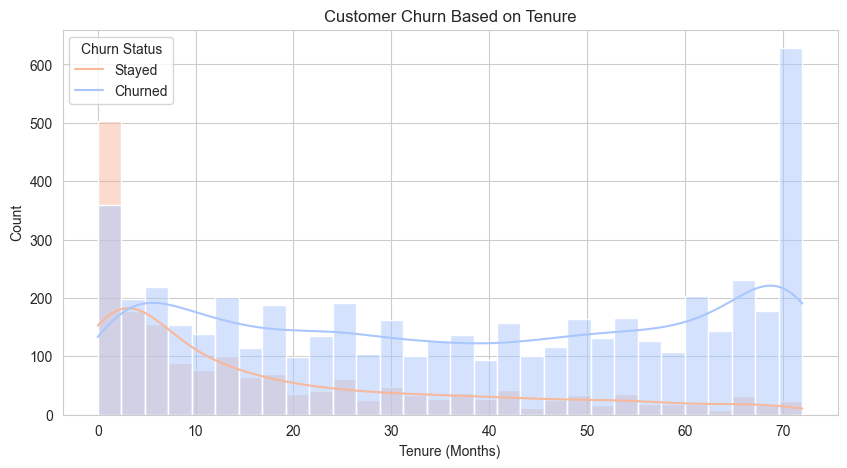

In [49]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="tenure", hue="Churn", kde=True, bins=30, palette="coolwarm")
plt.title("Customer Churn Based on Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Count")
plt.legend(title="Churn Status", labels=["Stayed", "Churned"])
plt.show()

##### Interpretation and insights
1. High churn in the early months: Churned are relatively high in the initial months (around 0-10 months tenure), indicating a higher churn rate for newer customers.

2. Churn decreases as tenure increases: Churned shows a general downward trend as tenure increases, suggesting that longer-tenured customers are less likely to churn.

3. Higher retention for longer tenure: Stayed and the blue trend line (stayed) generally increase with tenure, indicating that customers with longer tenure are more likely to stay.

4. Peak of "Stayed" customers around 70 months: The blue trend line peaks around 70 months, suggesting a significant number of customers who have been with the company for a long time.

5. Distribution of Tenure: The bars show the distribution of tenure among customers. There are more customers with shorter tenure (0-20 months) compared to longer tenure (50-70 months).

##### Business Implications

This graph highlights the importance of focusing on customer retention, especially in the early months of their tenure. The company could consider strategies to reduce churn for newer customers. Some potential strategies include:
- Onboarding programs to improve initial customer experience.
- Proactive communication and support for new customers.
- Identifying and addressing common issues faced by new customers.
- Building customer loyalty to encourage long-term retention.

In summary, the graph shows that churn is highest among newer customers and decreases as tenure increases.  The company should focus on strategies to improve early customer retention to minimize churn and maximize long-term customer value.

##### Comparing Churn by Monthly Charges

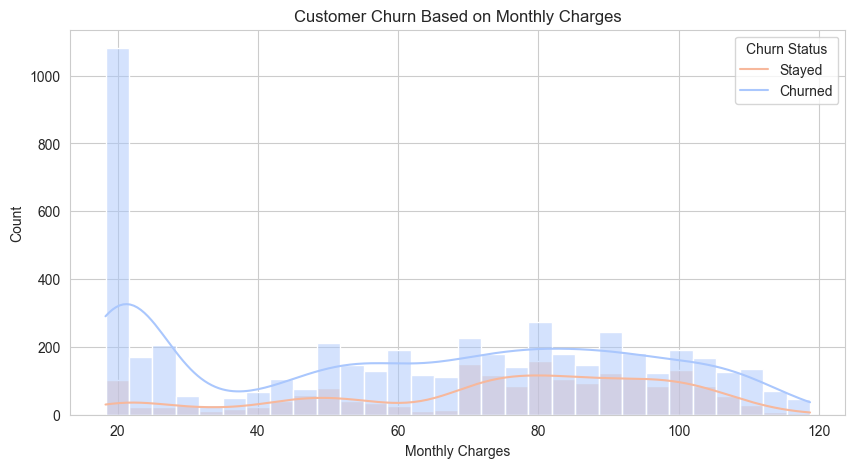

In [50]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", kde=True, bins=30, palette="coolwarm")
plt.title("Customer Churn Based on Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Count")
plt.legend(title="Churn Status", labels=["Stayed", "Churned"])
plt.show()

##### Interpretation and insight
1. High churn at lower monthly charges: Churned are relatively high in the lower monthly charge ranges (around $20-$40), indicating a higher churn rate for customers paying less per month.

2. Churn decreases as monthly charges increase: Churned generally shows a downward trend as monthly charges increase, suggesting that customers paying more per month are less likely to churn.

3. Higher retention for higher monthly charges: Stayed and the blue trend line (stayed) generally increase with monthly charges, indicating that customers paying more per month are more likely to stay.

4. Distribution of Monthly Charges: The bars show the distribution of monthly charges among customers. There are more customers with lower monthly charges (around $20-$40) compared to higher monthly charges (around $80-$100).

##### Business Implications
This graph suggests a potential correlation between monthly charges and customer churn.  Customers paying less are more likely to churn. The company could consider strategies to address this, such as:
- Bundling services or offering value-added features to increase monthly charges.
- Understanding the reasons behind high churn among lower-paying customers (e.g., perceived lack of value, budget constraints).
- Targeting marketing efforts towards higher-value customers.
- Potentially adjusting pricing strategies to minimize churn among lower-paying customers.

In summary, the graph shows that churn is highest among customers paying lower monthly charges and decreases as monthly charges increase.  The company should investigate the reasons behind this correlation and develop strategies to improve retention across all customer segments.

#### Deeper insights

##### Correlation analysis

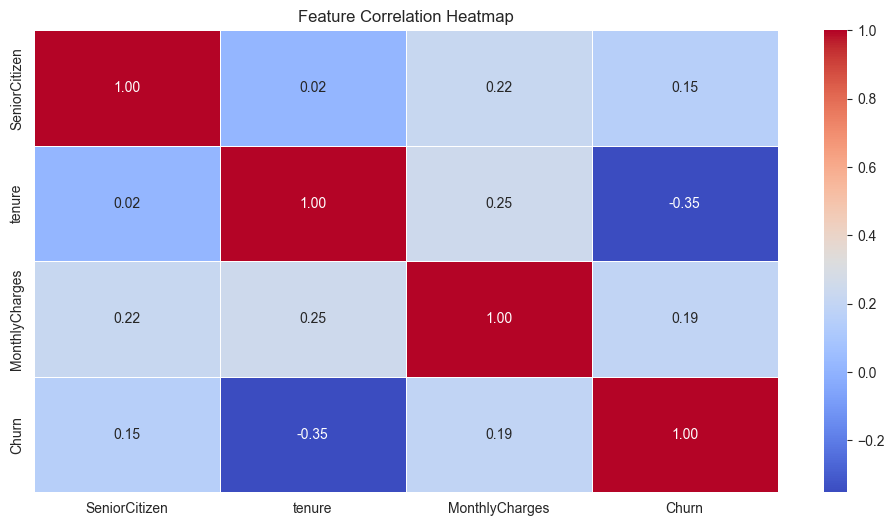

In [51]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Convert 'Churn' column to numeric (Yes = 1, No = 0)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Select only numeric columns
numeric_df = df.select_dtypes(include=[np.number])

# Compute correlation matrix
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

##### Interpretation and insights
1. Churn and Tenure have a moderate negative correlation (-0.35). This means that customers with longer tenure are less likely to churn, which aligns with our previous analysis of the "Customer Churn Based on Tenure" graph.

2. Churn and MonthlyCharges have a weak positive correlation (0.19). This suggests that customers with slightly higher monthly charges are slightly more likely to churn. While the correlation is weak, it still indicates a potential relationship.

3. Churn and SeniorCitizen have a weak positive correlation (0.15). Senior citizens are slightly more likely to churn, although the correlation is weak.

4. Tenure and MonthlyCharges have a moderate positive correlation (0.25). Customers with longer tenure tend to have slightly higher monthly charges.

5. SeniorCitizen and Tenure have a very weak positive correlation (0.02). There is practically no linear relationship between being a senior citizen and tenure.

6. SeniorCitizen and MonthlyCharges have a weak positive correlation (0.22). Senior citizens tend to have slightly higher monthly charges.

7. Diagonal cells are 1.00. This is because each variable is perfectly correlated with itself.

##### Business Implications
This heatmap confirms some of the insights gained from previous graphs and provides further information about the relationships between variables. The company should consider:
- Focusing on improving retention for customers with shorter tenure, as tenure is a significant predictor of churn.
- Investigating the reasons behind the weak positive correlation between churn and monthly charges, as well as churn and senior citizens, to identify potential areas for improvement.
- Considering the moderate positive correlation between tenure and monthly charges when designing pricing strategies.

In summary, the correlation heatmap provides a concise overview of the relationships between different variables and highlights the importance of tenure in predicting churn.  The company should use this information to develop targeted strategies for customer retention.

##### Feature Importance using Machine Learning
Training a simple Random Forest model to see which factors contribute most to churn.

C:\Users\hp\AppData\Local\Temp\ipykernel_9132\1176820225.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importance, y=X.columns, palette="coolwarm")


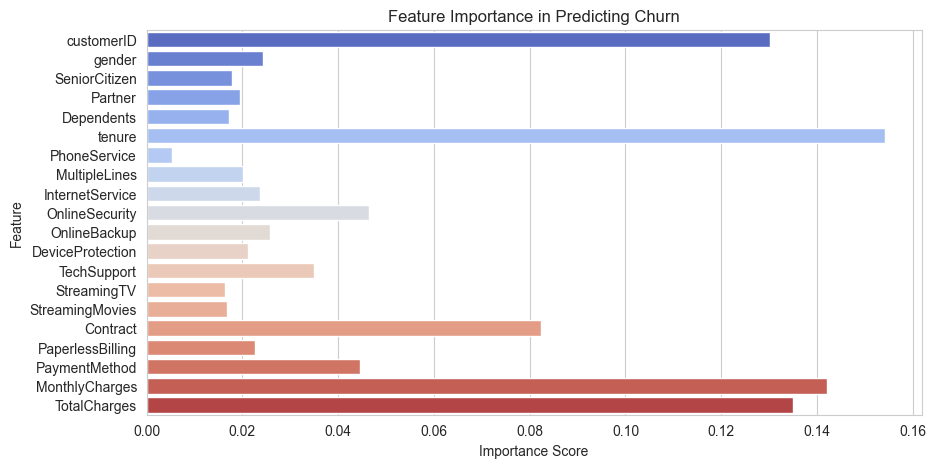

In [52]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Encode categorical variables
df_encoded = df.apply(lambda col: LabelEncoder().fit_transform(col) if col.dtype == 'object' else col)

# Define X (features) and y (target)
X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest Model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Extract feature importance
feature_importance = model.feature_importances_

# Plot feature importance
plt.figure(figsize=(10, 5))
sns.barplot(x=feature_importance, y=X.columns, palette="coolwarm")
plt.title("Feature Importance in Predicting Churn")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

##### Interpretation and insight
1. TotalCharges is the most important feature. The "TotalCharges" bar is the longest and darkest red, indicating it has the highest importance score. This suggests that the total amount a customer has paid is a strong predictor of churn.

2. MonthlyCharges is also highly important. "MonthlyCharges" is the second most important feature, signifying that the monthly amount a customer pays is a significant factor in churn prediction.

3. Contract type is moderately important. "Contract" is the third most important feature, indicating that the type of contract a customer has (e.g., month-to-month, one-year, two-year) plays a role in predicting churn.

4. PaymentMethod is moderately important. "PaymentMethod" also has a moderate importance score, suggesting that the way a customer pays influences their likelihood of churning.

5. Other features have varying degrees of importance. Features like "gender," "SeniorCitizen," "Partner," "Dependents," "tenure," and various service-related features have relatively lower importance scores but still contribute to the model's predictions.

##### Business Implications
This graph provides valuable insights into the factors that drive customer churn. The company should consider:
- Focusing on strategies to address churn related to "TotalCharges" and "MonthlyCharges". This could include pricing adjustments, value-added services, or targeted promotions.
- Analyzing the impact of contract type and payment method on churn. This could lead to adjustments in contract offerings or payment options.
- Recognizing that while "CustomerID" is not important for prediction, it's essential for tracking individual customers and their behavior.
- Understanding the influence of other features (though less significant) to refine customer segmentation and targeted marketing.

In summary, the graph highlights the key factors that contribute to customer churn, with "TotalCharges" and "MonthlyCharges" being the most influential.  The company should leverage these insights to develop effective churn reduction strategies.

##### Customer Segmentation using Clustering.
using K-Means Clustering to segment customers into different groups based on behavior.

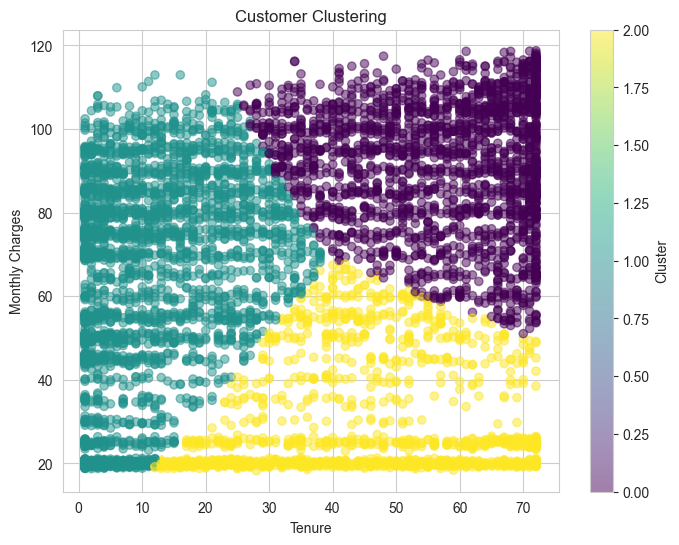

In [53]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Convert 'Churn' column to numeric (Yes = 1, No = 0)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Convert 'TotalCharges' to numeric, replacing spaces with NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Drop missing values
df = df.dropna(subset=["TotalCharges"])

# Select features for clustering
features = df[["tenure", "MonthlyCharges", "TotalCharges"]]

# Scale data
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42)
df["Cluster"] = kmeans.fit_predict(features_scaled)

# Visualize clusters
plt.figure(figsize=(8, 6))
plt.scatter(df["tenure"], df["MonthlyCharges"], c=df["Cluster"], cmap="viridis", alpha=0.5)
plt.xlabel("Tenure")
plt.ylabel("Monthly Charges")
plt.title("Customer Clustering")
plt.colorbar(label="Cluster")
plt.show()

##### Interpretation and insights
1. Distinct Clusters: The graph reveals that the clustering algorithm has identified distinct groups of customers based on their tenure and monthly charges. The different colors clearly separate these groups visually.

2. Cluster 1 (Purple/Dark Blue): High Tenure, High Monthly Charges. The cluster in the upper right (purple/dark blue) represents customers with high tenure (longer length of stay) and high monthly charges. These are likely long-term, high-value customers.

3. Cluster 2 (Yellow): Moderate to High Tenure, Low Monthly Charges. The cluster in the lower right (yellow) represents customers with moderate to high tenure (longer length of stay) but low monthly charges. These could be customers on older, less expensive plans or those who bundle services for discounts.

4. Cluster 3 (Teal/Green): Low to Moderate Tenure, Moderate Monthly Charges. The cluster in the left half (teal/green) represents customers with low to moderate tenure (shorter length of stay) and moderate monthly charges. These are likely newer customers who are still in the early stages of their relationship with the company.

##### Business Implications
This clustering analysis provides valuable insights for customer segmentation and targeted marketing. The company can:
- Tailor strategies for each cluster. For example, the high-tenure, high-value customers (purple/dark blue) could be targeted with loyalty programs and exclusive offers.
- Investigate the reasons behind the low monthly charges for long-tenured customers (yellow). This could lead to upselling opportunities or adjustments to pricing strategies.
- Focus on improving retention for newer customers (teal/green). This could involve targeted onboarding programs or personalized communication.

In summary, the graph effectively visualizes customer clusters based on tenure and monthly charges, providing a foundation for developing targeted strategies to improve customer retention and increase customer value.